In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import skfuzzy as fuzz

from skfuzzy import control as ctrl
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Input variables
temperature = ctrl.Antecedent(
    np.arange(0, 46, 1), "temperature"
)

humidity = ctrl.Antecedent(
    np.arange(0, 101, 1), "humidity"
)

wind_speed = ctrl.Antecedent(
    np.arange(0, 51, 1), "wind_speed"
)

# Output variable: comfort score from 0 to 100
comfort = ctrl.Consequent(
    np.arange(0, 101, 1), "comfort"
)

print("Input and output variables created.")

Input and output variables created.


In [4]:
# Temperature membership functions
temperature["low"] = fuzz.trapmf(
    temperature.universe, [0, 0, 10, 20]
)

temperature["medium"] = fuzz.trimf(
    temperature.universe, [10, 22, 32]
)

temperature["high"] = fuzz.trapmf(
    temperature.universe, [25, 35, 45, 45]
)


# Humidity membership functions
humidity["low"] = fuzz.trapmf(
    humidity.universe, [0, 0, 20, 40]
)

humidity["medium"] = fuzz.trimf(
    humidity.universe, [25, 50, 75]
)

humidity["high"] = fuzz.trapmf(
    humidity.universe, [60, 80, 100, 100]
)


# Wind speed membership functions
wind_speed["low"] = fuzz.trapmf(
    wind_speed.universe, [0, 0, 5, 15]
)

wind_speed["medium"] = fuzz.trimf(
    wind_speed.universe, [8, 20, 32]
)

wind_speed["high"] = fuzz.trapmf(
    wind_speed.universe, [25, 35, 50, 50]
)


# Output membership functions
comfort["poor"] = fuzz.trapmf(
    comfort.universe, [0, 0, 15, 30]
)

comfort["moderate"] = fuzz.trimf(
    comfort.universe, [20, 40, 60]
)

comfort["comfortable"] = fuzz.trimf(
    comfort.universe, [50, 68, 85]
)

comfort["excellent"] = fuzz.trapmf(
    comfort.universe, [75, 90, 100, 100]
)

print("Membership functions defined.")

Membership functions defined.


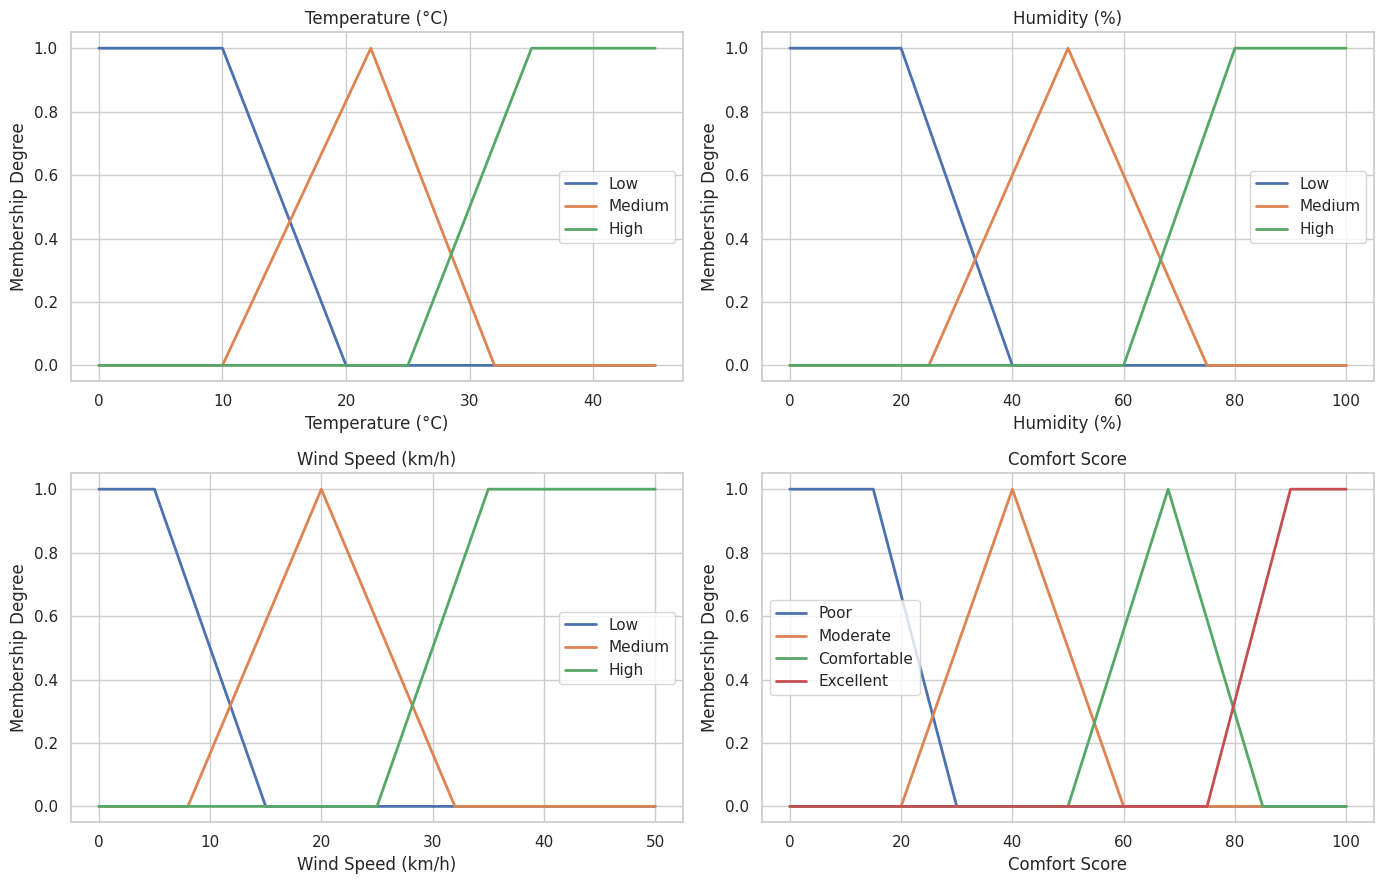

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

variables = [
    (temperature, "Temperature (°C)"),
    (humidity, "Humidity (%)"),
    (wind_speed, "Wind Speed (km/h)"),
    (comfort, "Comfort Score")
]

for ax, (variable, title) in zip(axes.flat, variables):
    for term in variable.terms:
        ax.plot(
            variable.universe,
            variable[term].mf,
            linewidth=2,
            label=term.capitalize()
        )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Membership Degree")
    ax.set_ylim(-0.05, 1.05)
    ax.legend()

plt.tight_layout()
plt.show()

In [6]:
# Output category order
output_levels = [
    "poor",
    "moderate",
    "comfortable",
    "excellent"
]

# Temperature contribution to comfort
temperature_score = {
    "low": 1,
    "medium": 3,
    "high": 1
}

# Humidity contribution
humidity_score = {
    "low": 0,
    "medium": 0,
    "high": -1
}

# Wind contribution
wind_score = {
    "low": 1,
    "medium": 0,
    "high": -1
}

rules = []

for t in ["low", "medium", "high"]:
    for h in ["low", "medium", "high"]:
        for w in ["low", "medium", "high"]:

            # Combine the illustrative rule scores
            score = (
                temperature_score[t]
                + humidity_score[h]
                + wind_score[w]
            )

            # Map to the output fuzzy category
            if score <= 0:
                output_term = "poor"
            elif score == 1:
                output_term = "moderate"
            elif score == 2:
                output_term = "comfortable"
            else:
                output_term = "excellent"

            rule = ctrl.Rule(
                temperature[t]
                & humidity[h]
                & wind_speed[w],
                comfort[output_term],
                label=f"T_{t}_H_{h}_W_{w}"
            )

            rules.append(rule)

print("Total rules created:", len(rules))

Total rules created: 27


In [7]:
# Create the Mamdani control system
comfort_system = ctrl.ControlSystem(rules)

# Create the simulation object
comfort_simulation = ctrl.ControlSystemSimulation(
    comfort_system
)

print("Mamdani Fuzzy Inference System is ready.")

Mamdani Fuzzy Inference System is ready.


In [8]:
def predict_comfort(temp, hum, wind):
    """
    Predict a fuzzy comfort score between 0 and 100.
    """

    if not 0 <= temp <= 45:
        raise ValueError("Temperature must be between 0 and 45 °C.")

    if not 0 <= hum <= 100:
        raise ValueError("Humidity must be between 0 and 100%.")

    if not 0 <= wind <= 50:
        raise ValueError("Wind speed must be between 0 and 50 km/h.")

    simulation = ctrl.ControlSystemSimulation(comfort_system)

    simulation.input["temperature"] = float(temp)
    simulation.input["humidity"] = float(hum)
    simulation.input["wind_speed"] = float(wind)

    simulation.compute()

    return float(simulation.output["comfort"])


# Example input
temp = 28
hum = 70
wind = 12

score = predict_comfort(temp, hum, wind)

def get_category(score):
    if score <= 25:
        return "Poor"
    elif score <= 50:
        return "Moderate"
    elif score <= 75:
        return "Comfortable"
    else:
        return "Excellent"

print(f"Temperature: {temp} °C")
print(f"Humidity: {hum}%")
print(f"Wind Speed: {wind} km/h")
print(f"Comfort Score: {score:.2f}/100")
print(f"Comfort Category: {get_category(score)}")

Temperature: 28 °C
Humidity: 70%
Wind Speed: 12 km/h
Comfort Score: 50.46/100
Comfort Category: Comfortable


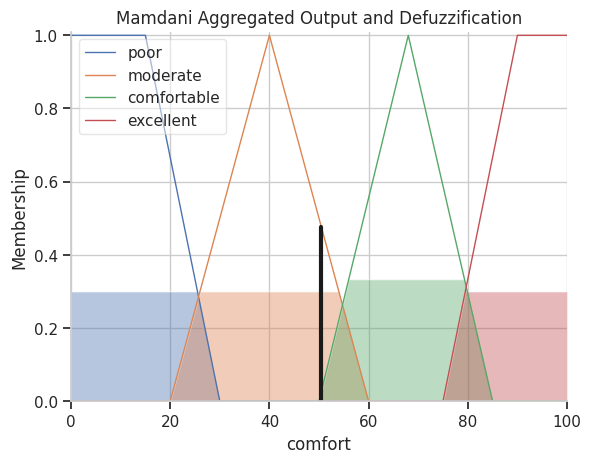

Centroid defuzzified score: 50.46


In [9]:
# Recompute the example so the simulation has its result
comfort_simulation.input["temperature"] = temp
comfort_simulation.input["humidity"] = hum
comfort_simulation.input["wind_speed"] = wind
comfort_simulation.compute()

# Display the aggregated fuzzy output
comfort.view(sim=comfort_simulation)
plt.title("Mamdani Aggregated Output and Defuzzification")
plt.show()

# Display the crisp score
print("Centroid defuzzified score:",
      round(comfort_simulation.output["comfort"], 2))

In [10]:
print("Mamdani rule base")
print("=" * 60)

for i, rule in enumerate(rules, start=1):
    print(f"Rule {i}: {rule.label}")

Mamdani rule base
Rule 1: T_low_H_low_W_low
Rule 2: T_low_H_low_W_medium
Rule 3: T_low_H_low_W_high
Rule 4: T_low_H_medium_W_low
Rule 5: T_low_H_medium_W_medium
Rule 6: T_low_H_medium_W_high
Rule 7: T_low_H_high_W_low
Rule 8: T_low_H_high_W_medium
Rule 9: T_low_H_high_W_high
Rule 10: T_medium_H_low_W_low
Rule 11: T_medium_H_low_W_medium
Rule 12: T_medium_H_low_W_high
Rule 13: T_medium_H_medium_W_low
Rule 14: T_medium_H_medium_W_medium
Rule 15: T_medium_H_medium_W_high
Rule 16: T_medium_H_high_W_low
Rule 17: T_medium_H_high_W_medium
Rule 18: T_medium_H_high_W_high
Rule 19: T_high_H_low_W_low
Rule 20: T_high_H_low_W_medium
Rule 21: T_high_H_low_W_high
Rule 22: T_high_H_medium_W_low
Rule 23: T_high_H_medium_W_medium
Rule 24: T_high_H_medium_W_high
Rule 25: T_high_H_high_W_low
Rule 26: T_high_H_high_W_medium
Rule 27: T_high_H_high_W_high


In [11]:
def baseline_comfort(temp, hum, wind):
    """
    Illustrative non-fuzzy baseline for comparison.
    This is not a validated weather comfort index.
    """

    # Best temperature assumed to be around 22 °C
    temp_penalty = abs(temp - 22) * 2.2

    # Penalize very low or very high humidity
    humidity_penalty = max(0, hum - 55) * 0.25
    humidity_penalty += max(0, 35 - hum) * 0.15

    # Penalize stronger winds
    wind_penalty = max(0, wind - 10) * 0.7

    score = 100 - temp_penalty - humidity_penalty - wind_penalty

    return float(np.clip(score, 0, 100))


print("Fuzzy score:",
      round(predict_comfort(28, 70, 12), 2))

print("Baseline score:",
      round(baseline_comfort(28, 70, 12), 2))

Fuzzy score: 50.46
Baseline score: 81.65


In [12]:
rng = np.random.default_rng(42)

n_samples = 150

test_data = pd.DataFrame({
    "Temperature": rng.uniform(0, 45, n_samples),
    "Humidity": rng.uniform(0, 100, n_samples),
    "Wind_Speed": rng.uniform(0, 50, n_samples)
})

test_data["Mamdani_Score"] = test_data.apply(
    lambda row: predict_comfort(
        row["Temperature"],
        row["Humidity"],
        row["Wind_Speed"]
    ),
    axis=1
)

test_data["Baseline_Score"] = test_data.apply(
    lambda row: baseline_comfort(
        row["Temperature"],
        row["Humidity"],
        row["Wind_Speed"]
    ),
    axis=1
)

test_data["Mamdani_Category"] = test_data[
    "Mamdani_Score"
].apply(get_category)

display(test_data.head(10))

test_data.to_csv("weather_comfort_results.csv", index=False)
print("Saved weather_comfort_results.csv")

,Temperature,Humidity,Wind_Speed,Mamdani_Score,Baseline_Score,Mamdani_Category
0,34.828022,82.629192,38.949818,11.714656,44.606181,Poor
1,19.749530,89.616077,6.727610,87.180682,86.394946,Excellent
2,38.636906,14.024909,26.803402,33.465442,48.490161,Moderate
3,31.381561,55.403614,25.711144,42.877645,68.261861,Moderate
4,4.237981,10.857574,42.878607,11.666667,34.287169,Poor
5,43.903006,67.224009,23.139968,27.416215,39.559407,Moderate
6,34.251287,28.123378,19.254475,40.000000,65.537544,Moderate
7,35.372894,65.942263,31.978164,13.859727,52.459353,Poor
8,5.765113,72.699461,13.323166,28.285775,57.532168,Moderate
9,20.267367,76.864749,6.988421,90.187493,90.722021,Excellent


Saved weather_comfort_results.csv


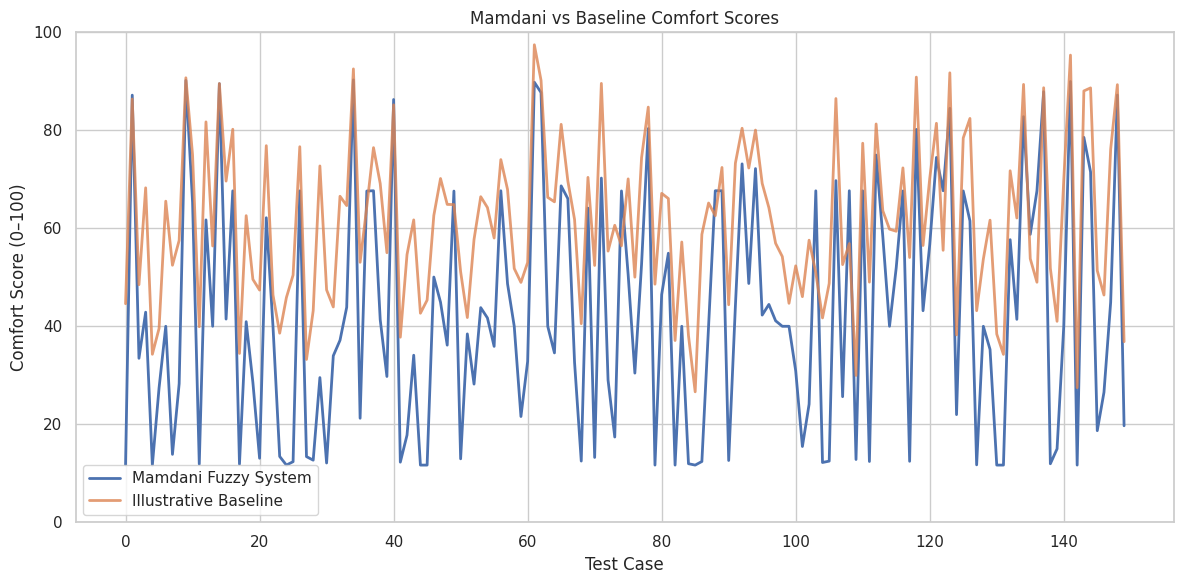

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_data.index,
    test_data["Mamdani_Score"],
    label="Mamdani Fuzzy System",
    linewidth=2
)

plt.plot(
    test_data.index,
    test_data["Baseline_Score"],
    label="Illustrative Baseline",
    linewidth=2,
    alpha=0.8
)

plt.xlabel("Test Case")
plt.ylabel("Comfort Score (0–100)")
plt.title("Mamdani vs Baseline Comfort Scores")
plt.legend()
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

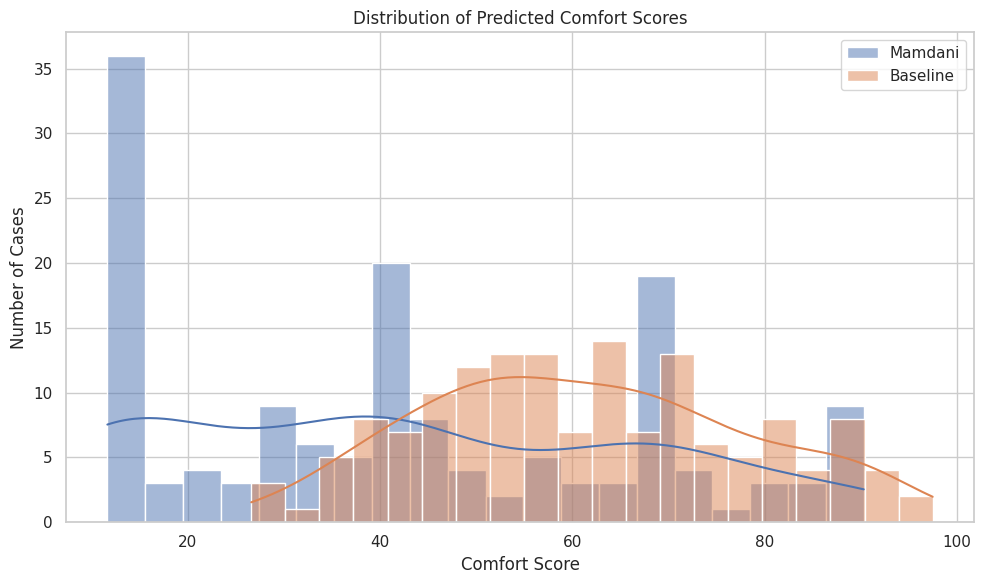

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    test_data["Mamdani_Score"],
    bins=20,
    kde=True,
    label="Mamdani",
    alpha=0.5
)

sns.histplot(
    test_data["Baseline_Score"],
    bins=20,
    kde=True,
    label="Baseline",
    alpha=0.5
)

plt.xlabel("Comfort Score")
plt.ylabel("Number of Cases")
plt.title("Distribution of Predicted Comfort Scores")
plt.legend()
plt.tight_layout()
plt.show()

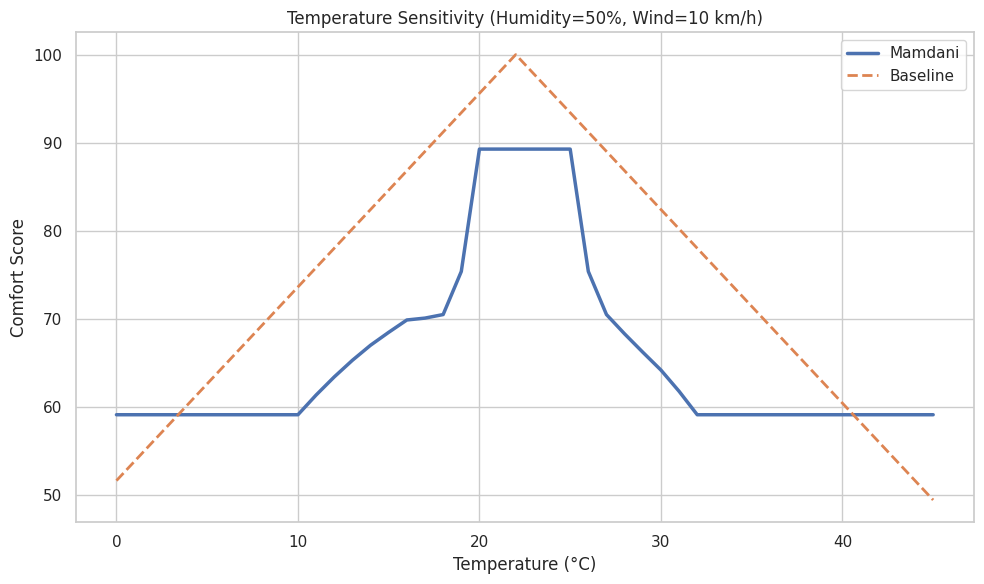

In [15]:
temperatures = np.arange(0, 46, 1)

fixed_humidity = 50
fixed_wind = 10

fuzzy_scores = [
    predict_comfort(t, fixed_humidity, fixed_wind)
    for t in temperatures
]

baseline_scores = [
    baseline_comfort(t, fixed_humidity, fixed_wind)
    for t in temperatures
]

plt.figure(figsize=(10, 6))

plt.plot(
    temperatures,
    fuzzy_scores,
    label="Mamdani",
    linewidth=2.5
)

plt.plot(
    temperatures,
    baseline_scores,
    label="Baseline",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Comfort Score")
plt.title(
    f"Temperature Sensitivity "
    f"(Humidity={fixed_humidity}%, Wind={fixed_wind} km/h)"
)

plt.legend()
plt.tight_layout()
plt.show()

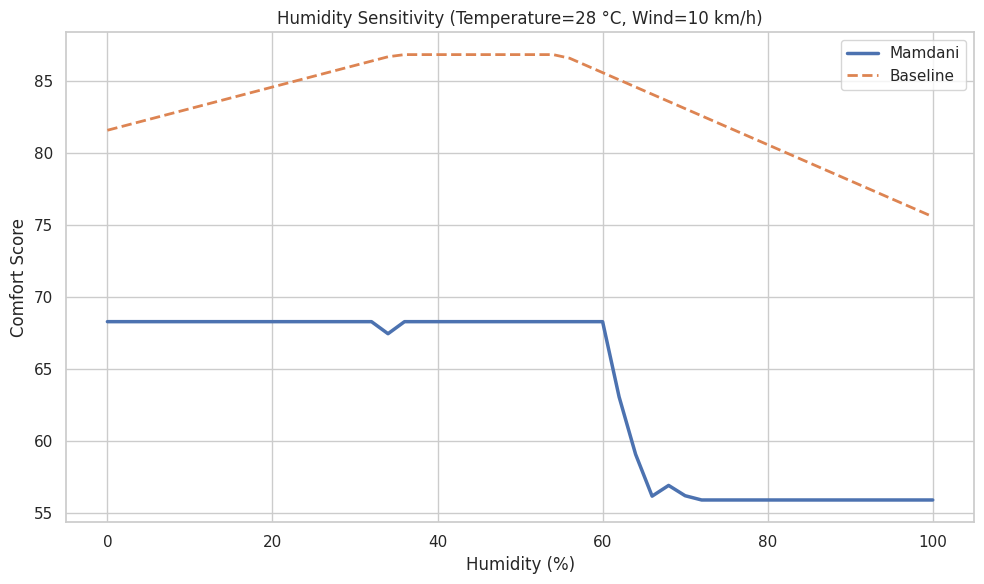

In [16]:
humidities = np.arange(0, 101, 2)

fixed_temp = 28
fixed_wind = 10

humidity_fuzzy = [
    predict_comfort(fixed_temp, h, fixed_wind)
    for h in humidities
]

humidity_baseline = [
    baseline_comfort(fixed_temp, h, fixed_wind)
    for h in humidities
]

plt.figure(figsize=(10, 6))

plt.plot(
    humidities,
    humidity_fuzzy,
    label="Mamdani",
    linewidth=2.5
)

plt.plot(
    humidities,
    humidity_baseline,
    label="Baseline",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Humidity (%)")
plt.ylabel("Comfort Score")
plt.title(
    f"Humidity Sensitivity "
    f"(Temperature={fixed_temp} °C, Wind={fixed_wind} km/h)"
)

plt.legend()
plt.tight_layout()
plt.show()

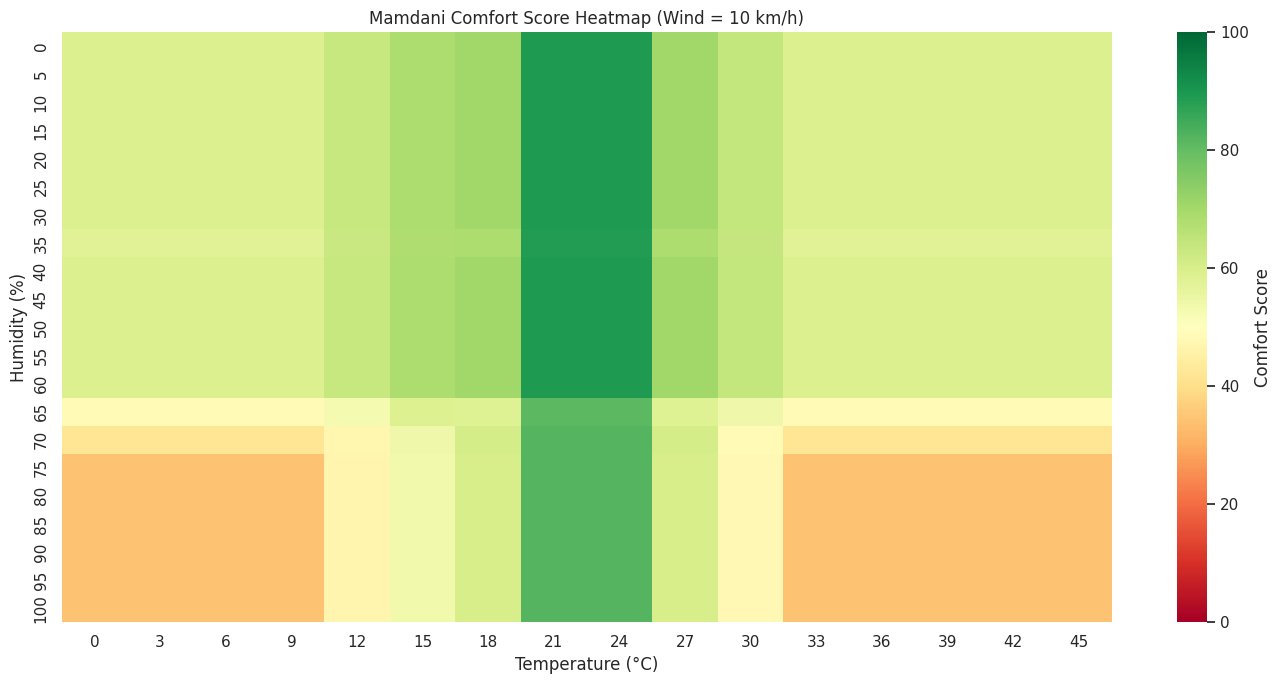

In [17]:
temp_values = np.arange(0, 46, 3)
humidity_values = np.arange(0, 101, 5)

heatmap_scores = np.zeros(
    (len(humidity_values), len(temp_values))
)

for i, h in enumerate(humidity_values):
    for j, t in enumerate(temp_values):
        heatmap_scores[i, j] = predict_comfort(
            t, h, 10
        )

plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_scores,
    xticklabels=temp_values,
    yticklabels=humidity_values,
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    annot=False,
    cbar_kws={"label": "Comfort Score"}
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Mamdani Comfort Score Heatmap (Wind = 10 km/h)")
plt.tight_layout()
plt.show()

In [18]:
summary = pd.DataFrame({
    "Metric": [
        "Mean Score",
        "Median Score",
        "Minimum Score",
        "Maximum Score",
        "Standard Deviation"
    ],
    "Mamdani": [
        test_data["Mamdani_Score"].mean(),
        test_data["Mamdani_Score"].median(),
        test_data["Mamdani_Score"].min(),
        test_data["Mamdani_Score"].max(),
        test_data["Mamdani_Score"].std()
    ],
    "Baseline": [
        test_data["Baseline_Score"].mean(),
        test_data["Baseline_Score"].median(),
        test_data["Baseline_Score"].min(),
        test_data["Baseline_Score"].max(),
        test_data["Baseline_Score"].std()
    ]
})

display(summary.round(2))

print("\nComfort category counts:")
display(
    test_data["Mamdani_Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Count")
)

,Metric,Mamdani,Baseline
0,Mean Score,42.65,61.24
1,Median Score,40.00,60.22
2,Minimum Score,11.67,26.62
3,Maximum Score,90.29,97.46
4,Standard Deviation,24.51,16.55



Comfort category counts:


,Category,Count
0,Moderate,52
1,Poor,44
2,Comfortable,39
3,Excellent,15
